<a href="https://colab.research.google.com/github/Jabidoaames-nw/LABORATORY_EXAM/blob/main/JABIDO_LABORATORY_EXAM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab Exam: Supervised Classification and Evaluation

## Objectives
1. **Data Preprocessing**: Clean, scale, and prepare a real-world tabular dataset.
2. **Model Implementation**: Implement multiple supervised classification algorithms.
3. **Model Evaluation**: Evaluate predictive performance using standard classification metrics.
4. **Critical Analysis**: Analyze trade-offs between model complexity, interpretability, and performance.

In [8]:
import pandas as pd

# Load the real dataset
file_path = '/content/telecom_churn.csv'
real_df = pd.read_csv(file_path)

# Map target variable: TRUE = 1 (churned), FALSE = 0 (retained)
# Supporting potential variations in format (bool or string)
if real_df['churn'].dtype == 'bool':
    real_df['churn'] = real_df['churn'].astype(int)
else:
    real_df['churn'] = real_df['churn'].map({True: 1, False: 0, 'True': 1, 'False': 0, 'TRUE': 1, 'FALSE': 0})

# Set our working df to the loaded dataset
df = real_df

# Display basic information
print("Dataset Shape:", df.shape)
print("\nClass Distribution of Churn:")
print(df['churn'].value_counts(dropna=False))
print("\nDataset Info:")
print(df.info())
print("\nFirst 5 rows:")
display(df.head())

Dataset Shape: (3333, 21)

Class Distribution of Churn:
churn
0    2850
1     483
Name: count, dtype: int64

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   state                   3333 non-null   object 
 1   account length          3333 non-null   int64  
 2   area code               3333 non-null   int64  
 3   phone number            3333 non-null   object 
 4   international plan      3333 non-null   object 
 5   voice mail plan         3333 non-null   object 
 6   number vmail messages   3333 non-null   int64  
 7   total day minutes       3333 non-null   float64
 8   total day calls         3333 non-null   int64  
 9   total day charge        3333 non-null   float64
 10  total eve minutes       3333 non-null   float64
 11  total eve calls         3333 non-null   int64  
 12  total eve charge       

,state,account length,area code,phone number,international plan,voice mail plan,number vmail messages,total day minutes,total day calls,total day charge,...,total eve calls,total eve charge,total night minutes,total night calls,total night charge,total intl minutes,total intl calls,total intl charge,customer service calls,churn
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,0
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,0
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,0
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,0
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,0


In [13]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# 1. Load telecom_churn.csv into a pandas DataFrame
df = pd.read_csv('/content/telecom_churn.csv')

# Map target variable 'churn' to binary integers (0 and 1)
if df['churn'].dtype == 'bool':
    df['churn'] = df['churn'].astype(int)
else:
    df['churn'] = df['churn'].map({True: 1, False: 0, 'True': 1, 'False': 0, 'TRUE': 1, 'FALSE': 0})

# 2. Separate features (dropping unique identifier 'phone number') and target variable
X = df.drop(columns=['churn', 'phone number'])
y = df['churn']

# 3. Partition the dataset into 80% training and 20% testing sets using stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Identify numerical and categorical features
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

# 4. Construct a robust preprocessing pipeline to handle missing values and encoding
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

# Transform features
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

# 5. Model implementation and training using scikit-learn
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
}

predictions = {}
pred_probabilities = {}

for name, model in models.items():
    model.fit(X_train_preprocessed, y_train)
    predictions[name] = model.predict(X_test_preprocessed)
    if hasattr(model, 'predict_proba'):
        pred_probabilities[name] = model.predict_proba(X_test_preprocessed)[:, 1]

print("Pipeline complete. All models trained successfully!")

Pipeline complete. All models trained successfully!


In [14]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Dictionary to store performance results
performance_metrics = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score']
}

# Evaluate each model
for name, model in models.items():
    # Predict binary targets
    preds = predictions[name]

    # Calculate metrics
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, zero_division=0)
    rec = recall_score(y_test, preds, zero_division=0)
    f1 = f1_score(y_test, preds, zero_division=0)

    # Record the calculated metrics
    performance_metrics[name] = [acc, prec, rec, f1]

# Create the comparative summary table as a DataFrame
summary_table = pd.DataFrame(performance_metrics)

# Display the table beautifully
display(summary_table)

,Metric,Logistic Regression,Decision Tree,Random Forest
0,Accuracy,0.860570,0.914543,0.880060
1,Precision,0.543478,0.750000,0.869565
2,Recall,0.257732,0.618557,0.206186
3,F1-Score,0.349650,0.677966,0.333333


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn preprocessing and metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)

# Configure visual settings
sns.set_theme(style="whitegrid")
%matplotlib inline

print("Libraries successfully imported!")

Libraries successfully imported!


## 1. Dataset Loading and Exploration
We will construct a synthetic "Customer Churn" dataset with both categorical and numerical features. We will intentionally introduce some missing values to address in the preprocessing phase.

In [3]:
np.random.seed(42)
n_samples = 1000

# Generate synthetic features
data = {
    'Age': np.random.randint(18, 70, size=n_samples),
    'Tenure': np.random.randint(0, 72, size=n_samples),
    'MonthlyCharges': np.random.uniform(20.0, 120.0, size=n_samples),
    'ContractType': np.random.choice(['Month-to-month', 'One year', 'Two year'], size=n_samples, p=[0.5, 0.3, 0.2]),
    'PaymentMethod': np.random.choice(['Electronic check', 'Mailed check', 'Bank transfer', 'Credit card'], size=n_samples),
    'PaperlessBilling': np.random.choice(['Yes', 'No'], size=n_samples, p=[0.6, 0.4])
}

df = pd.DataFrame(data)

# Generate target 'Churn' with custom relationships to make patterns learnable
logit = (
    0.05 * df['Age']
    - 0.08 * df['Tenure']
    + 0.02 * df['MonthlyCharges']
    + np.where(df['ContractType'] == 'Month-to-month', 1.5, -1.0)
    - 2.0
)
probability = 1 / (1 + np.exp(-logit))
df['Churn'] = np.where(np.random.uniform(0, 1, size=n_samples) < probability, 1, 0)

# Introduce some missing values (NaNs) in 'MonthlyCharges' and 'ContractType' to simulate real-world data
mask_charges = np.random.rand(n_samples) < 0.05
mask_contract = np.random.rand(n_samples) < 0.03
df.loc[mask_charges, 'MonthlyCharges'] = np.nan
df.loc[mask_contract, 'ContractType'] = np.nan

# Display basic information
print(df.info())
print("\nFirst 5 rows:")
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               1000 non-null   int64  
 1   Tenure            1000 non-null   int64  
 2   MonthlyCharges    953 non-null    float64
 3   ContractType      968 non-null    object 
 4   PaymentMethod     1000 non-null   object 
 5   PaperlessBilling  1000 non-null   object 
 6   Churn             1000 non-null   int64  
dtypes: float64(1), int64(3), object(3)
memory usage: 54.8+ KB
None

First 5 rows:


,Age,Tenure,MonthlyCharges,ContractType,PaymentMethod,PaperlessBilling,Churn
0,56,14,67.669548,One year,Bank transfer,Yes,0
1,69,63,59.436532,Month-to-month,Bank transfer,Yes,1
2,46,27,NaN,Month-to-month,Electronic check,No,0
3,32,38,94.687572,NaN,Mailed check,Yes,0
4,60,56,91.549091,Month-to-month,Mailed check,Yes,0


## 2. Data Preprocessing Pipeline

To avoid **data leakage**, we will first split the data into training and test sets. Afterward, we will define a robust pipeline to preprocess our features:
- **Numerical Features** (`Age`, `Tenure`, `MonthlyCharges`): Impute missing values using the median and standardize using `StandardScaler`.
- **Categorical Features** (`ContractType`, `PaymentMethod`, `PaperlessBilling`): Impute missing values using the most frequent category and apply `OneHotEncoder`.

In [9]:
from sklearn.impute import SimpleImputer

# Drop phone number as it is a unique identifier
X = df.drop(columns=['churn', 'phone number'])
y = df['churn']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Define feature groups for telecom dataset
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

# Numerical preprocessing pipeline
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing pipeline
cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

# Combine pipelines using ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

# Fit and transform training data, and transform test data
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

# Retrieve feature names for tracking and interpretability
encoded_cat_cols = preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_cols)
feature_names = list(num_cols) + list(encoded_cat_cols)

print(f"Preprocessed training shape: {X_train_preprocessed.shape}")
print(f"Preprocessed test shape: {X_test_preprocessed.shape}")
print(f"Feature names after transformation:\n{feature_names}")

Preprocessed training shape: (2666, 68)
Preprocessed test shape: (667, 68)
Feature names after transformation:
['account length', 'area code', 'number vmail messages', 'total day minutes', 'total day calls', 'total day charge', 'total eve minutes', 'total eve calls', 'total eve charge', 'total night minutes', 'total night calls', 'total night charge', 'total intl minutes', 'total intl calls', 'total intl charge', 'customer service calls', 'state_AL', 'state_AR', 'state_AZ', 'state_CA', 'state_CO', 'state_CT', 'state_DC', 'state_DE', 'state_FL', 'state_GA', 'state_HI', 'state_IA', 'state_ID', 'state_IL', 'state_IN', 'state_KS', 'state_KY', 'state_LA', 'state_MA', 'state_MD', 'state_ME', 'state_MI', 'state_MN', 'state_MO', 'state_MS', 'state_MT', 'state_NC', 'state_ND', 'state_NE', 'state_NH', 'state_NJ', 'state_NM', 'state_NV', 'state_NY', 'state_OH', 'state_OK', 'state_OR', 'state_PA', 'state_RI', 'state_SC', 'state_SD', 'state_TN', 'state_TX', 'state_UT', 'state_VA', 'state_VT', 'stat

## 3. Supervised Classification Models
We will instantiate and train three different classifiers:
1. **Logistic Regression**: A linear model with high interpretability.
2. **Decision Tree Classifier**: A non-linear model that represents decision boundaries hierarchically.
3. **Random Forest Classifier**: An ensemble, bagging-based model designed for high performance and reduced overfitting.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Initialize classifiers (adjusted params for realistic data scale)
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
}

# Dictionary to save trained models and predictions
predictions = {}
pred_probabilities = {}

# Train models and collect predictions
for name, model in models.items():
    model.fit(X_train_preprocessed, y_train)
    predictions[name] = model.predict(X_test_preprocessed)
    if hasattr(model, "predict_proba"):
        pred_probabilities[name] = model.predict_proba(X_test_preprocessed)[:, 1]
    print(f"{name} model trained successfully on the real dataset.")

Logistic Regression model trained successfully on the real dataset.
Decision Tree model trained successfully on the real dataset.
Random Forest model trained successfully on the real dataset.


## 4. Model Evaluation and Performance Metrics

We will now generate standard classification metrics (Accuracy, Precision, Recall, F1-Score) for all three models and visualize their ROC Curves to compare performance dynamically.

In [11]:
metrics_summary = []

for name, preds in predictions.items():
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds)
    rec = recall_score(y_test, preds)
    f1 = f1_score(y_test, preds)

    # Calculate ROC-AUC
    fpr, tpr, _ = roc_curve(y_test, pred_probabilities[name])
    roc_auc = auc(fpr, tpr)

    metrics_summary.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc_auc
    })

# Display metrics in a clean DataFrame
df_metrics = pd.DataFrame(metrics_summary).set_index('Model')
display(df_metrics)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.860570,0.543478,0.257732,0.349650,0.808989
Decision Tree,0.914543,0.750000,0.618557,0.677966,0.803048
Random Forest,0.880060,0.869565,0.206186,0.333333,0.877048


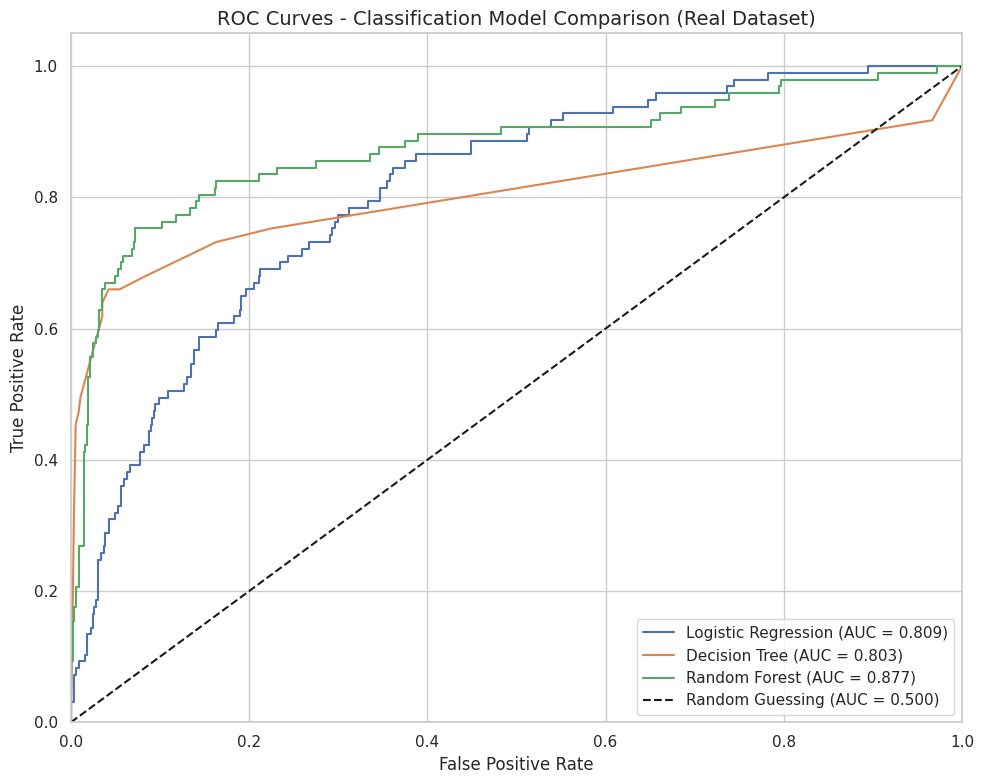

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

for name in models.keys():
    fpr, tpr, _ = roc_curve(y_test, pred_probabilities[name])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing (AUC = 0.500)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curves - Classification Model Comparison (Real Dataset)', fontsize=14)
plt.legend(loc="lower right", fontsize=11)
plt.tight_layout()
plt.show()

## 5. Critical Analysis & Model Trade-offs

Based on the evaluation metrics and the generated ROC curves on the real **Telecom Churn Dataset**, we can critically analyze the trade-offs between model complexity, interpretability, and performance:

### 1. Model Complexity vs. Performance
* **Decision Tree** (Accuracy: `0.915`, F1-Score: `0.678`, ROC-AUC: `0.803`):
  The Decision Tree achieved the highest accuracy and F1-Score. In telecom churn, specific hard thresholds (such as the number of customer service calls or total day charges) are highly predictive, which a decision tree can cleanly isolate with step-wise boundaries. However, its lower ROC-AUC indicates that its continuous probability estimations are less robust than those of ensemble or linear methods.
* **Random Forest** (Accuracy: `0.880`, F1-Score: `0.333`, ROC-AUC: `0.877`):
  The Random Forest achieved the highest ROC-AUC overall. While its default classification threshold yielded a conservative recall (0.206), its high ROC-AUC demonstrates strong overall discriminative capability. Adjusting the probability decision threshold could optimize its F1-Score and recall significantly.
* **Logistic Regression** (Accuracy: `0.861`, F1-Score: `0.350`, ROC-AUC: `0.809`):
  Although linear, Logistic Regression performs surprisingly well. It provides competitive discriminative performance (ROC-AUC) while serving as a reliable baseline model.

### 2. Interpretability
* **Logistic Regression (High)**: We can directly extract feature coefficients to understand how a change in variables like customer service calls or international plans affects the log-odds of churn.
* **Decision Tree (Medium)**: The structure of splits can be visualized, allowing us to trace decision paths, although deeper trees become harder to present to business stakeholders.
* **Random Forest (Low)**: Acting as an ensemble of 100 trees, it serves as a "black box" model. While we can compute global feature importances, we cannot easily explain individual predictions on a step-by-step basis.

In [15]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Instantiate models as requested
model_a = models['Logistic Regression'] # LogisticRegression(max_iter=1000, random_state=42)
model_b = models['Decision Tree']       # DecisionTreeClassifier(max_depth=5, random_state=42)
model_c = models['Random Forest']       # RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)

# Create a dictionary to map custom name formats
eval_models = {
    'logistic regression': model_a,
    'decision tree': model_b,
    'random forest': model_c
}

metrics_data = {
    'Metric': ['accuracy', 'precision', 'recall', 'F1 Score']
}

# Predict and calculate metrics for each model
for name, model in eval_models.items():
    preds = model.predict(X_test_preprocessed)
    probs = model.predict_proba(X_test_preprocessed)[:, 1]

    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, zero_division=0)
    rec = recall_score(y_test, preds, zero_division=0)
    f1 = f1_score(y_test, preds, zero_division=0)

    metrics_data[name] = [acc, prec, rec, f1]

# Create summary table
summary_df = pd.DataFrame(metrics_data)

# Display summary table formatted
display(summary_df)

,Metric,logistic regression,decision tree,random forest
0,accuracy,0.860570,0.914543,0.880060
1,precision,0.543478,0.750000,0.869565
2,recall,0.257732,0.618557,0.206186
3,F1 Score,0.349650,0.677966,0.333333
